----------------------------------------------------------------------------------------------------
Total baris setelah preprocessing : 6390
Data latih - 80%                  : 5085 baris
Data uji - 20%                    : 1305 baris
Data latih dimulai                : 2010-02-12
Data uji dimulai                  : 2012-04-13
Rata-rata penjualan data uji      : 1,037,672.68
----------------------------------------------------------------------------------------------------
Random Forest tanpa sales lag      MAE =    62,764.39 | RMSE =    92,489.50 | R2 = 0.9700
----------------------------------------------------------------------------------------------------
XGBoost tanpa sales lag            MAE =    65,403.34 | RMSE =    95,240.62 | R2 = 0.9681
----------------------------------------------------------------------------------------------------
Naif (minggu sebelumnya)           MAE =    54,343.62 | RMSE =    82,736.58 | R2 = 0.9760
------------------------------------------------

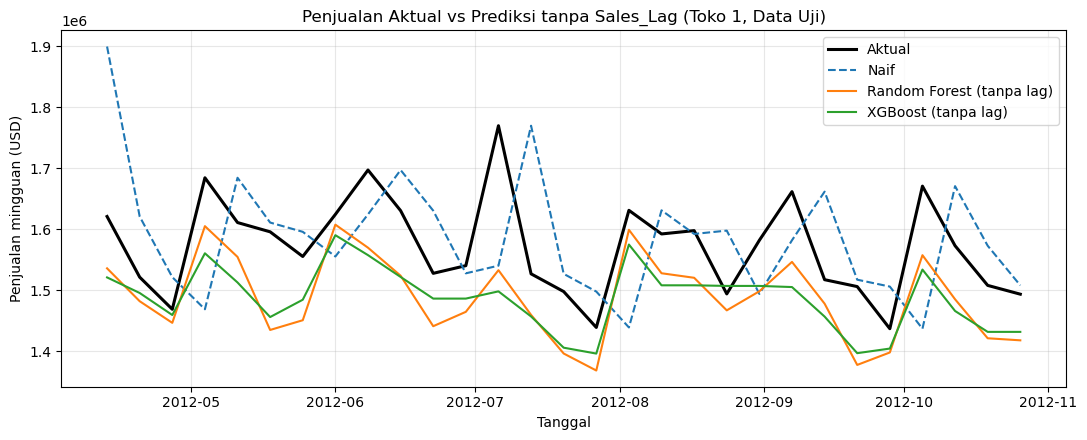

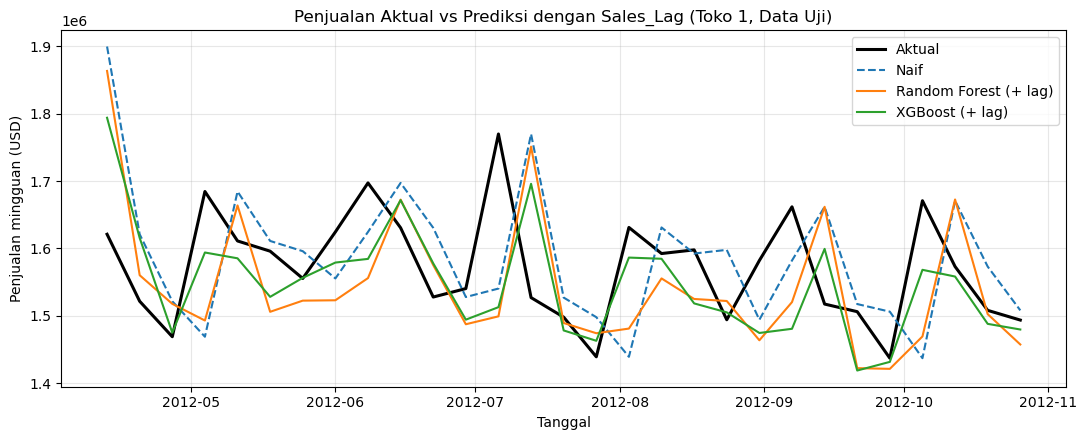

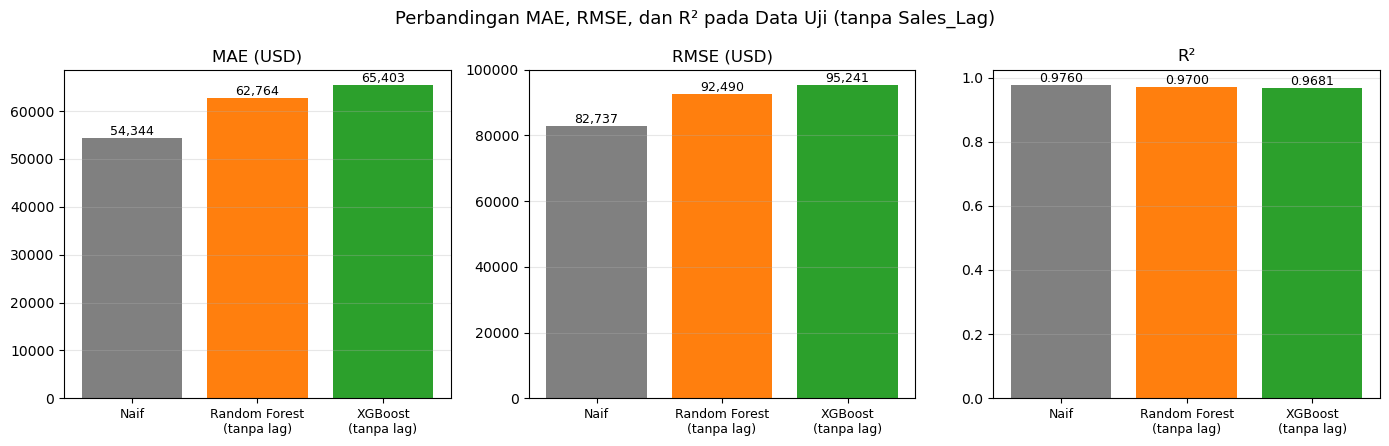

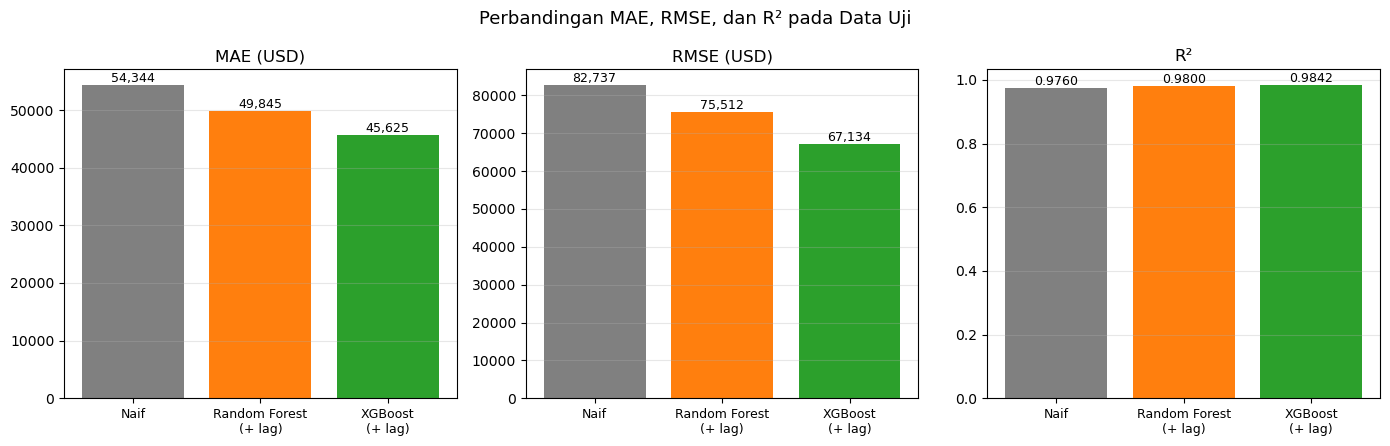

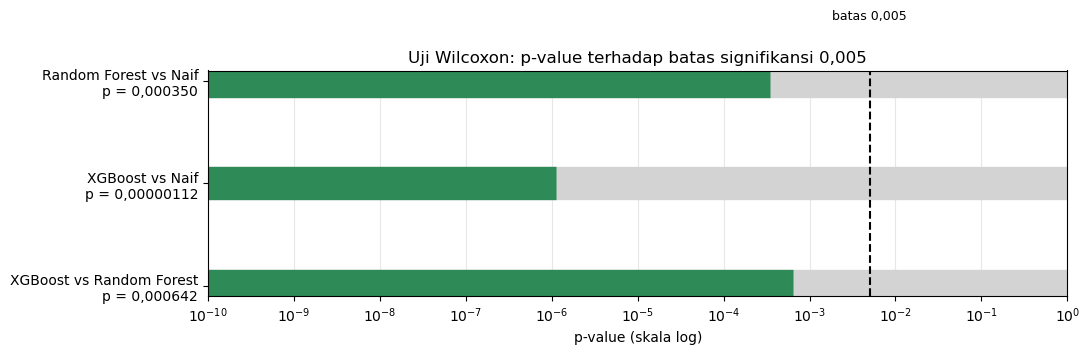

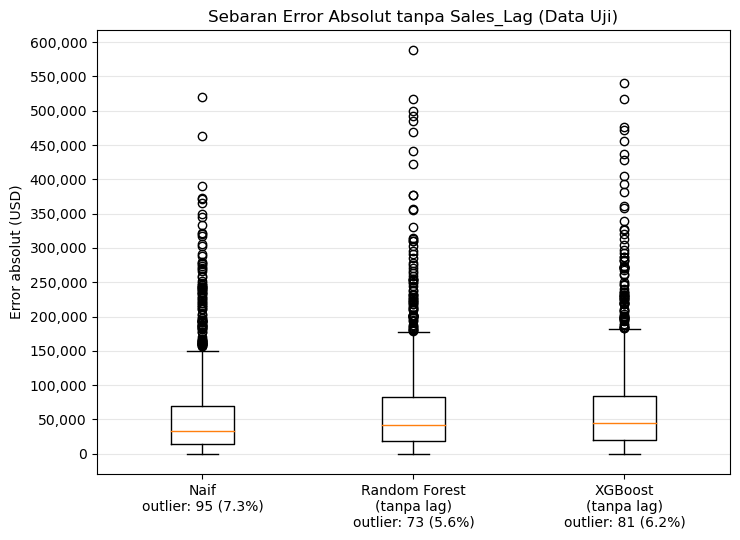

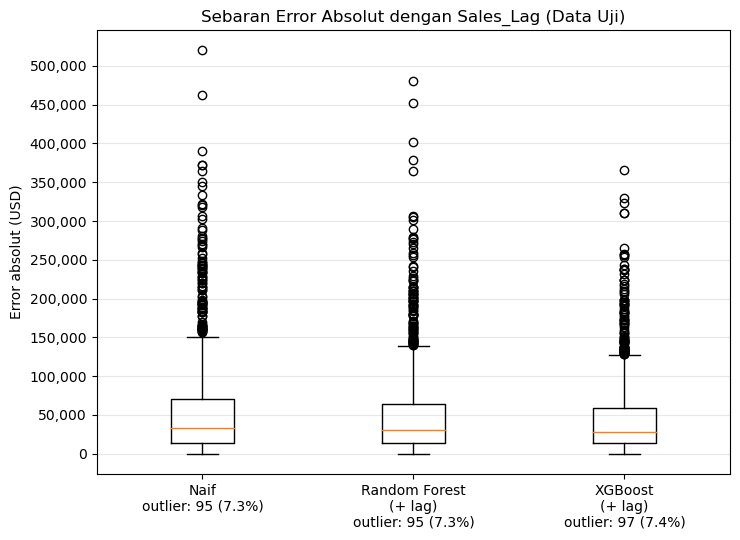

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator, MultipleLocator, FuncFormatter
from math import ceil, log10
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
ALPHA = 0.005
TARGET = "Weekly_Sales"
LAG = "Sales_Lag1"
FEATS_NOLAG = ["Store", "Holiday_Flag", "Month", "WeekOfYear"]
FEATS_LAG = FEATS_NOLAG + [LAG]
PERSENTASE_TRAIN = 0.8

# langkah 1: Preprocessing dan pembagian data 80/20
print("-" * 100)

df = pd.read_csv("Dataset_Walmart.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
df["Month"] = df["Date"].dt.month
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
df[LAG] = df.groupby("Store")[TARGET].shift(1)
df = df.dropna(subset=[LAG]).reset_index(drop=True)

unique_dates = np.sort(df["Date"].unique())
cutoff = unique_dates[int(len(unique_dates) * PERSENTASE_TRAIN)]
train = df[df["Date"] < cutoff].copy()
test = df[df["Date"] >= cutoff].copy()

print(f"Total baris setelah preprocessing : {len(df)}")
print(f"Data latih - {PERSENTASE_TRAIN*100:.0f}%                  : {len(train)} baris")
print(f"Data uji - {(1 - PERSENTASE_TRAIN)*100:.0f}%                    : {len(test)} baris")
print(f"Data latih dimulai                : {pd.Timestamp(train['Date'].min()).date()}")
print(f"Data uji dimulai                  : {pd.Timestamp(cutoff).date()}")
print(f"Rata-rata penjualan data uji      : {test[TARGET].mean():,.2f}")

y_test = test[TARGET].values

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

def print_metrics(name, m):
    print(f"{name:<34} MAE = {m['MAE']:>12,.2f} | RMSE = {m['RMSE']:>12,.2f} | R2 = {m['R2']:.4f}")

# langkah 2:Random Forest (tanpa Sales_Lag)
print("-" * 100)
rf_nolag = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_nolag.fit(train[FEATS_NOLAG], train[TARGET])
pred_rf_nolag = rf_nolag.predict(test[FEATS_NOLAG])
m_rf_nolag = metrics(y_test, pred_rf_nolag)
print_metrics("Random Forest tanpa sales lag", m_rf_nolag)

# langkah 3: XGBoost (tanpa Sales_Lag)
print("-" * 100)
xgb_nolag = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=SEED)
xgb_nolag.fit(train[FEATS_NOLAG], train[TARGET])
pred_xgb_nolag = xgb_nolag.predict(test[FEATS_NOLAG])
m_xgb_nolag = metrics(y_test, pred_xgb_nolag)
print_metrics("XGBoost tanpa sales lag", m_xgb_nolag)

# langkah 4: Model naif (menyalin penjualan minggu sebelumnya)
print("-" * 100)
pred_naive = test[LAG].values
m_naive = metrics(y_test, pred_naive)
print_metrics("Naif (minggu sebelumnya)", m_naive)

# langkah 5: Random Forest dan XGBoost dengan Sales_Lag
print("-" * 100)
print("Train Model Random Forest dan XGBoost dengan Sales_Lag\n")
rf_lag = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_lag.fit(train[FEATS_LAG], train[TARGET])
pred_rf_lag = rf_lag.predict(test[FEATS_LAG])
m_rf_lag = metrics(y_test, pred_rf_lag)
xgb_lag = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=SEED)
xgb_lag.fit(train[FEATS_LAG], train[TARGET])
pred_xgb_lag = xgb_lag.predict(test[FEATS_LAG])
m_xgb_lag = metrics(y_test, pred_xgb_lag)

print_metrics("Random Forest + sales lag", m_rf_lag)
print_metrics("XGBoost + sales lag", m_xgb_lag)
print_metrics("Naif (pembanding)", m_naive)
print("-" * 100)

# langkah 6: Uji Wilcoxon (batas signifikansi = 0,005)
print("\nUji Wilcoxon (batas signifikansi = 0,005)")
print("=" * 100)

err_naive = np.abs(y_test - pred_naive)
err_rf = np.abs(y_test - pred_rf_lag)
err_xgb = np.abs(y_test - pred_xgb_lag)

def wilcoxon_ringkasan(err_a, err_b, name_a, name_b):
    d = err_a - err_b
    n = np.count_nonzero(d)
    W, p = wilcoxon(err_a, err_b)  # W = min(W+, W-), p = p-value dua sisi
    mean_w = n * (n + 1) / 4
    sd_w = np.sqrt(n * (n + 1) * (2 * n + 1) / 24)
    z = (W - mean_w) / sd_w
    return {
        "Pasangan": f"{name_a} vs {name_b}",
        "n (selisih non-nol)": n,
        "W = min(W+, W-)": W,
        "z": round(z, 3),
        "p-value": p,
        "Keputusan": "Signifikan" if p < ALPHA else "Tidak signifikan",
    }

pairs = [
    (err_rf, err_naive, "Random Forest", "Naif"),
    (err_xgb, err_naive, "XGBoost", "Naif"),
    (err_xgb, err_rf, "XGBoost", "Random Forest"),
]

wilcox_results = [wilcoxon_ringkasan(a, b, na, nb) for a, b, na, nb in pairs]

tampil = pd.DataFrame(wilcox_results)[
    ["Pasangan", "n (selisih non-nol)", "W = min(W+, W-)", "z", "p-value", "Keputusan"]
].copy()
tampil["p-value"] = tampil["p-value"].apply(lambda p: f"{p:.7f}".replace(".", ","))

print("RINGKASAN UJI WILCOXON")
print(tampil.to_string(index=False))


# ===== Visualisasi Hasil Prediksi dan Evaluasi Model =====================================
# 1) Visualisasi hasil prediksi 3 algoritma tanpa sales lag
STORE_ID = 1
t = test.assign(Pred_RF=pred_rf_nolag, Pred_XGB=pred_xgb_nolag, Pred_Naif=pred_naive)
t = t[t["Store"] == STORE_ID].sort_values("Date")

plt.figure(figsize=(11, 4.5))
plt.plot(t["Date"], t[TARGET], label="Aktual", color="black", linewidth=2.2)
plt.plot(t["Date"], t["Pred_Naif"], label="Naif", linestyle="--", color="tab:blue")
plt.plot(t["Date"], t["Pred_RF"], label="Random Forest (tanpa lag)", color="tab:orange")
plt.plot(t["Date"], t["Pred_XGB"], label="XGBoost (tanpa lag)", color="tab:green")
plt.title(f"Penjualan Aktual vs Prediksi tanpa Sales_Lag (Toko {STORE_ID}, Data Uji)")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan mingguan (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2) prediksi 3 algoritma dengan sales lag
t = test.assign(Pred_RF=pred_rf_lag, Pred_XGB=pred_xgb_lag, Pred_Naif=pred_naive)
t = t[t["Store"] == STORE_ID].sort_values("Date")

plt.figure(figsize=(11, 4.5))
plt.plot(t["Date"], t[TARGET], label="Aktual", color="black", linewidth=2.2)
plt.plot(t["Date"], t["Pred_Naif"], label="Naif", linestyle="--", color="tab:blue")
plt.plot(t["Date"], t["Pred_RF"], label="Random Forest (+ lag)", color="tab:orange")
plt.plot(t["Date"], t["Pred_XGB"], label="XGBoost (+ lag)", color="tab:green")
plt.title(f"Penjualan Aktual vs Prediksi dengan Sales_Lag (Toko {STORE_ID}, Data Uji)")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan mingguan (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3) perbandingan MAE, RMSE, dan R² 3 algoritma pada data uji tanpa sales lag
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
nama = ["Naif", "Random Forest\n(tanpa lag)", "XGBoost\n(tanpa lag)"]
metrik = [m_naive, m_rf_nolag, m_xgb_nolag]
warna = ["gray", "tab:orange", "tab:green"]

for ax, key, judul in zip(axes, ["MAE", "RMSE", "R2"], ["MAE (USD)", "RMSE (USD)", "R²"]):
    nilai = [m[key] for m in metrik]
    bars = ax.bar(nama, nilai, color=warna)
    ax.set_title(judul)
    for bar, v in zip(bars, nilai):
        teks = f"{v:.4f}" if key == "R2" else f"{v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), teks,
                ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Perbandingan MAE, RMSE, dan R² pada Data Uji (tanpa Sales_Lag)", fontsize=13)
plt.tight_layout()
plt.show()

# 4) perbandingan MAE, RMSE, dan R² 3 algoritmapada data uji dengan sales lag
models_names = ["Naif", "Random Forest\n(+ lag)", "XGBoost\n(+ lag)"]
metric_list = [m_naive, m_rf_lag, m_xgb_lag]
colors = ["gray", "tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, key, title in zip(axes, ["MAE", "RMSE", "R2"], ["MAE (USD)", "RMSE (USD)", "R²"]):
    values = [m[key] for m in metric_list]
    bars = ax.bar(models_names, values, color=colors)
    ax.set_title(title)
    for bar, v in zip(bars, values):
        fmt = f"{v:.4f}" if key == "R2" else f"{v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), fmt,
                ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Perbandingan MAE, RMSE, dan R² pada Data Uji", fontsize=13)
plt.tight_layout()
plt.show()

# 5) visualisasi hasil uji Wilcoxon
FLOOR = 1e-10  # batas bawah tampilan sumbu x: 10^-10

def p_decimal(p, sig=3):
    if p <= 0:
        p = FLOOR
    n_dec = ceil(-log10(p)) + sig - 1
    return f"{p:.{n_dec}f}".replace(".", ",")

labels_text = [f"{r['Pasangan']}\np = {p_decimal(r['p-value'])}" for r in wilcox_results]

fig, ax = plt.subplots(figsize=(11, 3.8))
for i, r in enumerate(wilcox_results):
    p_disp = min(max(r["p-value"], FLOOR), 1)
    color = "seagreen" if r["p-value"] < ALPHA else "firebrick"
    ax.hlines(i, FLOOR, 1, colors="lightgray", linewidth=24)   # track penuh
    ax.hlines(i, FLOOR, p_disp, colors=color, linewidth=24)    # progress p-value

ax.axvline(ALPHA, color="black", linestyle="--", linewidth=1.5)
ax.text(ALPHA, -0.6, "batas 0,005", ha="center", fontsize=9)

ax.set_xscale("log")
ax.set_xlim(FLOOR, 1)

# Tick di setiap pangkat 10: 10^-10, 10^-9, ..., 10^0
exponents = list(range(-10, 1))
ax.xaxis.set_major_locator(FixedLocator([10.0 ** k for k in exponents]))
ax.xaxis.set_major_formatter(FixedFormatter([rf"$10^{{{k}}}$" for k in exponents]))
ax.xaxis.set_minor_locator(NullLocator())

ax.set_yticks(range(len(wilcox_results)))
ax.set_yticklabels(labels_text)
ax.invert_yaxis()
ax.set_xlabel("p-value (skala log)")
ax.set_title("Uji Wilcoxon: p-value terhadap batas signifikansi 0,005")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 6) visualisasi sebaran error absolut per model
err_rf_nolag = np.abs(y_test - pred_rf_nolag)
err_xgb_nolag = np.abs(y_test - pred_xgb_nolag)

def hitung_outlier(err):
    """Outlier = error di luar batas Tukey: di bawah Q1 - 1,5 IQR atau di atas Q3 + 1,5 IQR."""
    q1, q3 = np.percentile(err, [25, 75])
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    n_out = int(np.sum((err < batas_bawah) | (err > batas_atas)))
    return n_out

def boxplot_dengan_outlier(errs, nama, judul):
    labels = []
    for name, e in zip(nama, errs):
        n_out = hitung_outlier(e)
        pct = f"{n_out / len(e):.1%}".replace(".", ",")
        labels.append(f"{name}\noutlier: {n_out:,} ({pct})".replace(",", "."))

    plt.figure(figsize=(7.5, 5.5))
    plt.boxplot(errs)
    plt.xticks(range(1, len(errs) + 1), labels)
    plt.title(judul)
    plt.ylabel("Error absolut (USD)")
    ax = plt.gca()
    ax.yaxis.set_major_locator(MultipleLocator(50000))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# Boxplot 1: tanpa Sales_Lag
boxplot_dengan_outlier(
    [err_naive, err_rf_nolag, err_xgb_nolag],
    ["Naif", "Random Forest\n(tanpa lag)", "XGBoost\n(tanpa lag)"],
    "Sebaran Error Absolut tanpa Sales_Lag (Data Uji)",
)

# Boxplot 2: dengan Sales_Lag
boxplot_dengan_outlier(
    [err_naive, err_rf, err_xgb],
    ["Naif", "Random Forest\n(+ lag)", "XGBoost\n(+ lag)"],
    "Sebaran Error Absolut dengan Sales_Lag (Data Uji)",
)